# 作业3：NumPy、Matplotlib 与 pandas

- **学号**：20244081108
- **姓名**：王亨泰
- **环境**：独立 conda 虚拟环境 `pyda`（Python 3.11 + Jupyter）

## 第一个代码框：身份与环境记录

In [1]:
import hashlib
import os
import platform
import uuid

# 修改为自己的学号
STUDENT_ID = 20244081108

CONDA_ENV = os.environ.get("CONDA_DEFAULT_ENV", "pyda")
print(f"[Conda 环境] {CONDA_ENV}")

MACHINE_FP = hashlib.sha256(
    f"{platform.node()}|{platform.machine()}|{platform.system()}|{uuid.getnode()}".encode()
).hexdigest()[:16]

RUN_ID = f"{STUDENT_ID}-{MACHINE_FP}"
print(f"[学号]     {STUDENT_ID}")
print(f"[机器指纹] {MACHINE_FP}")
print(f"[RUN_ID]   {RUN_ID}")

[Conda 环境] pyda
[学号]     20244081108
[机器指纹] e8b54e0f27d3d000
[RUN_ID]   20244081108-e8b54e0f27d3d000


---
## 一、围绕半圆定律（Wigner 半圆定律）

对所有 $1 \le i \le j \le n$，独立地从均值为 0、方差为 $1/n$ 的正态分布抽取 $Z_{ij}$，再令 $Z_{ji}=Z_{ij}$，得到对称的 Wigner 矩阵。其特征值的标准化直方图随 $n$ 增大会趋近半圆密度

$$f(x)=\begin{cases}\displaystyle\frac{1}{2\pi}\sqrt{4-x^{2}},&|x|\leq2,\\0,&|x|>2.\end{cases}$$

先导入本部分需要的库，并设置中文字体（避免图中中文显示为方框）。

In [2]:
import numpy as np
import matplotlib.pyplot as plt

%matplotlib inline

# Windows 自带中文字体；axes.unicode_minus=False 让负号正常显示
plt.rcParams["font.sans-serif"] = ["Microsoft YaHei", "SimHei", "DejaVu Sans"]
plt.rcParams["axes.unicode_minus"] = False

### 1. `wigner_density(x)`：半圆密度函数

In [3]:
def wigner_density(x):
    """返回半圆密度在 x 处的值；输入为单个整数或浮点数（Python 或 NumPy 均可）。"""
    if np.abs(x) <= 2:
        # 按要求用 numpy.sqrt 计算平方根
        return float(np.sqrt(4 - x ** 2) / (2 * np.pi))
    return 0.0

In [4]:
# 关键位置取值
print("x=0  :", wigner_density(0), " 理论峰值 1/pi =", 1 / np.pi)
print("x=2  :", wigner_density(2))
print("x=-2 :", wigner_density(-2))
print("x=3  :", wigner_density(3), "（支撑之外为 0）")
print("返回类型:", type(wigner_density(0)))

# NumPy 标量同样适用
print("np.float64(1.0) ->", wigner_density(np.float64(1.0)))
print("np.int64(0)     ->", wigner_density(np.int64(0)))

x=0  : 0.3183098861837907  理论峰值 1/pi = 0.3183098861837907
x=2  : 0.0
x=-2 : 0.0
x=3  : 0.0 （支撑之外为 0）
返回类型: <class 'float'>
np.float64(1.0) -> 0.27566444771089604
np.int64(0)     -> 0.3183098861837907


**说明**：$|x|\le2$ 时返回 $\dfrac{\sqrt{4-x^2}}{2\pi}$，否则返回 `0.0`。平方根使用 `numpy.sqrt`，并用 `float()` 保证返回 Python 浮点数；NumPy 标量与 Python 标量都能正常计算。

### 2. `generate_wigner(n)`：生成 Wigner 矩阵

In [5]:
def generate_wigner(n):
    """返回一个随机的 n x n Wigner 矩阵；n 必须是正整数，否则抛出异常。"""
    # bool 是 int 的子类，先排除；非整数抛 TypeError
    if isinstance(n, bool) or not isinstance(n, (int, np.integer)):
        raise TypeError("n 必须是整数")
    if n <= 0:
        raise ValueError("n 必须是正整数")

    # 全部元素独立抽样，标准差为 sqrt(1/n)
    a = np.random.normal(loc=0.0, scale=np.sqrt(1.0 / n), size=(n, n))
    # 上三角（含对角线）保留抽样值；严格下三角由上三角转置镜像得到
    matrix = np.triu(a) + np.triu(a, 1).T
    return matrix

In [6]:
np.random.seed(42)
w4 = generate_wigner(4)
print(w4)
print("是否对称:", np.allclose(w4, w4.T))

# 上三角元素的方差应接近 1/n，均值接近 0
big = generate_wigner(1000)
upper_vals = big[np.triu_indices(1000)]
print("上三角元素均值:", round(upper_vals.mean(), 5), " 方差:", round(upper_vals.var(), 6), " 理论 1/n:", 0.001)

# 异常输入检查
for bad in [0, -3, 4.0, 2.5, "n", True]:
    try:
        generate_wigner(bad)
    except Exception as e:
        print(f"{bad!r:6} -> {type(e).__name__}: {e}")

[[ 0.24835708 -0.06913215  0.32384427  0.76151493]
 [-0.06913215 -0.11706848  0.78960641  0.38371736]
 [ 0.32384427  0.78960641 -0.23170885 -0.23286488]
 [ 0.76151493  0.38371736 -0.23286488 -0.28114376]]
是否对称: True
上三角元素均值: -7e-05  方差: 0.001001  理论 1/n: 0.001
0      -> ValueError: n 必须是正整数
-3     -> ValueError: n 必须是正整数
4.0    -> TypeError: n 必须是整数
2.5    -> TypeError: n 必须是整数
'n'    -> TypeError: n 必须是整数
True   -> TypeError: n 必须是整数


**说明**：先生成一个满的正态随机矩阵，`np.triu(a)` 保留含对角线的上三角，`np.triu(a, 1).T` 把严格上三角镜像到严格下三角，于是每个 $Z_{ij}\ (i\le j)$ 相互独立且 $Z_{ji}=Z_{ij}$。非整数抛 `TypeError`，非正整数抛 `ValueError`。

### 3. `get_spectrum(matrix)`：取全部特征值并排序

In [7]:
def get_spectrum(matrix):
    """返回对称矩阵的全部特征值，按非递减顺序排列。"""
    # eigvalsh 专门用于对称/厄米矩阵，返回值本身已按升序排列
    eigenvalues = np.linalg.eigvalsh(matrix)
    return np.sort(eigenvalues)  # 再显式排序一次，保证非递减

In [8]:
np.random.seed(1)
w5 = generate_wigner(5)
spectrum = get_spectrum(w5)
print(spectrum)
print("特征值数量:", spectrum.size)
print("是否非递减:", bool(np.all(np.diff(spectrum) >= 0)))

[-0.83797848 -0.02776023  0.57601612  0.75219186  1.32182784]
特征值数量: 5
是否非递减: True


### 4. 四个纵向子图：特征值直方图叠加半圆密度曲线

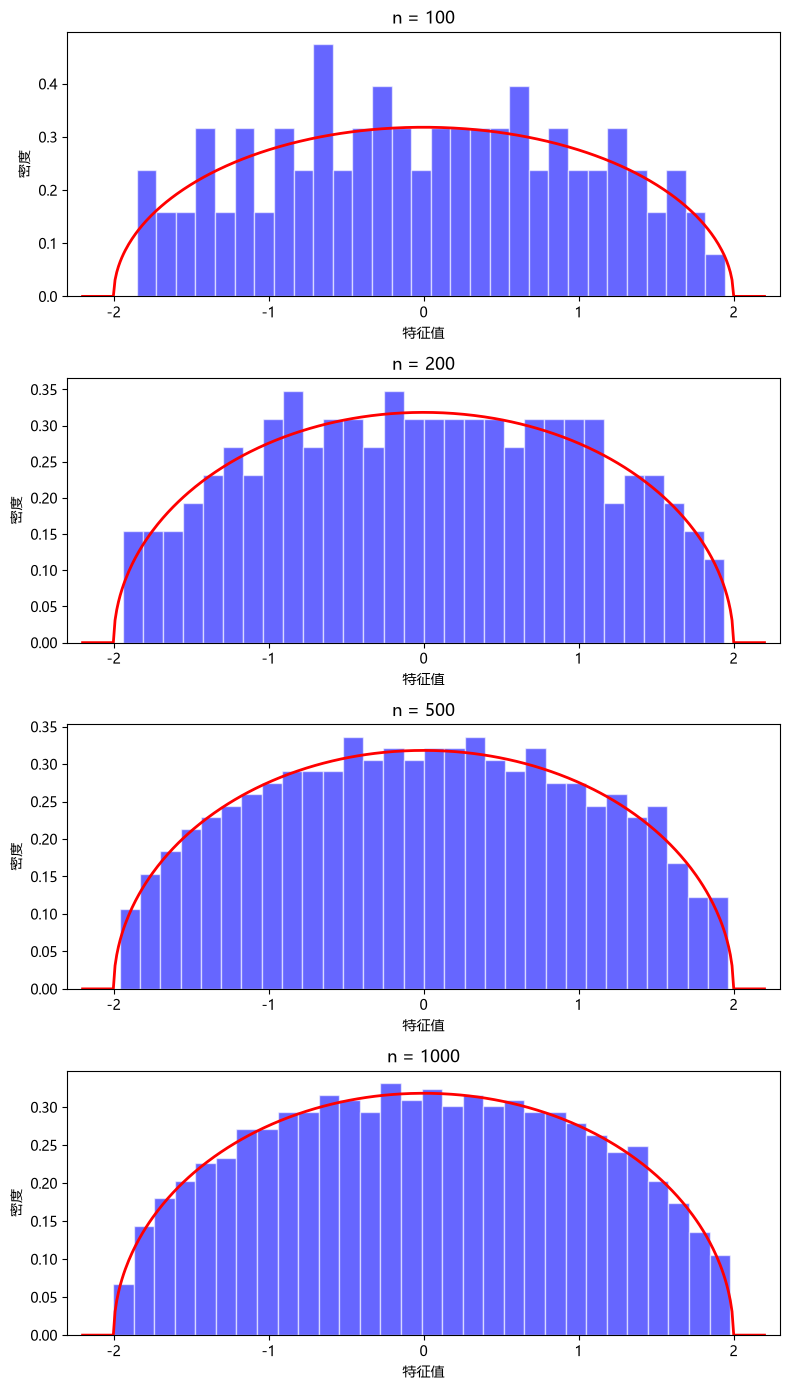

In [9]:
np.random.seed(0)
sizes = [100, 200, 500, 1000]
x_grid = np.linspace(-2.2, 2.2, 400)

fig, axes = plt.subplots(4, 1, figsize=(8, 14))
for ax, n in zip(axes, sizes):
    eig = get_spectrum(generate_wigner(n))
    ax.hist(eig, bins=30, density=True, color="blue", alpha=0.6, edgecolor="white")
    ax.plot(x_grid, [wigner_density(v) for v in x_grid], color="red", linewidth=2)
    ax.set_title(f"n = {n}")
    ax.set_xlabel("特征值")
    ax.set_ylabel("密度")
    ax.set_xlim(-2.3, 2.3)

plt.tight_layout()
plt.show()

**图形结论**：

- $n=100$ 时直方图边缘锯齿明显，两端（接近 $\pm2$）和顶部与红曲线偏差较大；
- $n=200$ 有所改善，但仍能看出起伏；
- **$n$ 大约达到 $500$ 时，半圆密度已经能较好地拟合特征值分布**；
- $n=1000$ 时蓝色直方图与红色密度曲线几乎重合，拟合效果最好。

下面用 Kolmogorov–Smirnov 检验作更严格的比较（可选任务）：KS 距离 $D$ 越小，说明经验分布与半圆理论分布越接近。

In [10]:
# 可选：KS 检验。先写出半圆分布的累积分布函数 CDF（向量化，可同时处理数组）
def wigner_cdf(x):
    x = np.asarray(x, dtype=float)
    inner = 0.5 + (x * np.sqrt(4 - x ** 2) + 4 * np.arcsin(x / 2)) / (4 * np.pi)
    # x<-2 取 0；x>2 取 1；中间取理论 CDF
    return np.select([x < -2, x > 2], [0.0, 1.0], default=inner)

from scipy import stats
import pandas as pd

ks_rows = []
for n in sizes:
    eig = get_spectrum(generate_wigner(n))
    d, p = stats.kstest(eig, wigner_cdf)
    ks_rows.append((n, round(d, 4), round(p, 4)))

ks_table = pd.DataFrame(ks_rows, columns=["n", "KS 距离 D", "p 值"])
ks_table

,n,KS 距离 D,p 值
0,100,0.0239,1.0
1,200,0.0132,1.0
2,500,0.0055,1.0
3,1000,0.0035,1.0


**KS 检验结论**：随 $n$ 增大，KS 距离 $D$ 整体减小，与图形观察一致——$n=500$ 起已经比较接近，$n=1000$ 时经验分布与理论半圆分布的距离最小。

---
## 二、Conway 的生命游戏

棋盘为二维 NumPy 数组，活细胞为 1、死细胞为 0，边界采用环绕（toroidal）方式。每个细胞有 8 个邻居，每一步同时更新。

### 1. `is_valid_board(board)`：判断是否为有效棋盘

In [11]:
def is_valid_board(board):
    """二维且元素仅为 0 或 1 时返回 True，否则返回 False（返回 Python 布尔值）。"""
    if not isinstance(board, np.ndarray):
        return False
    if board.ndim != 2:
        return False
    return bool(np.all((board == 0) | (board == 1)))

In [12]:
good = np.array([[0, 1], [1, 0]])
print("合法 0/1 棋盘:", is_valid_board(good), type(is_valid_board(good)))
print("含元素 2:", is_valid_board(np.array([[0, 2]])))
print("一维数组:", is_valid_board(np.array([1, 0, 1])))
print("普通 list:", is_valid_board([[0, 1]]))
print("字符串数组:", is_valid_board(np.array([["a", "b"]])))

合法 0/1 棋盘: True <class 'bool'>
含元素 2: False
一维数组: False
普通 list: False
字符串数组: False


### 2. `gol_step(board)`：前进一步（同时更新，环绕边界）

In [13]:
def gol_step(board):
    """返回下一步棋盘；输入无效时抛出异常。所有邻居计数都基于原棋盘。"""
    if not is_valid_board(board):
        raise ValueError("输入不是有效的生命游戏棋盘")

    # 用 np.roll 在两个方向上平移，自动实现环绕边界；累加 8 个方向的邻居
    neighbor_count = np.zeros_like(board, dtype=int)
    for dr in (-1, 0, 1):
        for dc in (-1, 0, 1):
            if dr == 0 and dc == 0:
                continue
            neighbor_count += np.roll(board, shift=(dr, dc), axis=(0, 1))

    alive = board == 1
    # 活细胞有 2 或 3 个邻居则存活；死细胞恰好 3 个邻居则复活
    survive = alive & ((neighbor_count == 2) | (neighbor_count == 3))
    born = (~alive) & (neighbor_count == 3)
    return (survive | born).astype(board.dtype)

In [14]:
# 滑翔机 glider：每 4 步整体向右下平移一格
glider = np.zeros((6, 6), dtype=int)
glider[1, 2] = 1
glider[2, 3] = 1
glider[3, 1:4] = 1
print("初始滑翔机:"); print(glider)

g = glider
for _ in range(4):
    g = gol_step(g)
print("4 步后（形状不变、位置平移）:"); print(g)

# 闪烁器 blinker：周期为 2 的振荡器
blinker = np.zeros((5, 5), dtype=int)
blinker[2, 1:4] = 1
b2 = gol_step(blinker)
print("横向闪烁器走一步变纵向:"); print(b2)
print("再一步还原:", bool(np.array_equal(gol_step(b2), blinker)))

# 无效输入
try:
    gol_step(np.array([[0, 1, 2]]))
except Exception as e:
    print(type(e).__name__, ":", e)

初始滑翔机:
[[0 0 0 0 0 0]
 [0 0 1 0 0 0]
 [0 0 0 1 0 0]
 [0 1 1 1 0 0]
 [0 0 0 0 0 0]
 [0 0 0 0 0 0]]
4 步后（形状不变、位置平移）:
[[0 0 0 0 0 0]
 [0 0 0 0 0 0]
 [0 0 0 1 0 0]
 [0 0 0 0 1 0]
 [0 0 1 1 1 0]
 [0 0 0 0 0 0]]
横向闪烁器走一步变纵向:
[[0 0 0 0 0]
 [0 0 1 0 0]
 [0 0 1 0 0]
 [0 0 1 0 0]
 [0 0 0 0 0]]
再一步还原: True
ValueError : 输入不是有效的生命游戏棋盘


**说明**：`np.roll` 平移后越过边界的元素会从另一侧出现，正好实现环绕边界。8 个方向的平移结果相加得到每个细胞的邻居数；整个过程只读取原棋盘，最后一次性生成新棋盘，满足“同时更新”的规则。

### 3. `draw_gol_board(board)`：把棋盘画成黑白方格

In [15]:
def draw_gol_board(board):
    """活细胞黑色、死细胞白色；不显示网格线、轴标签或刻度。"""
    if not is_valid_board(board):
        raise ValueError("输入不是有效的生命游戏棋盘")
    m, n = board.shape
    fig, ax = plt.subplots(figsize=(0.5 * n, 0.5 * m))
    ax.imshow(board, cmap=plt.get_cmap("binary"), aspect="equal")  # 0 白、1 黑
    ax.set_xticks([])
    ax.set_yticks([])
    return fig, ax

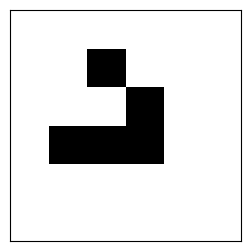

In [16]:
draw_gol_board(glider)
plt.show()

**说明**：`binary` 色图中低值（0）为白、高值（1）为黑；`set_xticks([])`、`set_yticks([])` 去掉刻度，轴标签留空，`imshow` 默认也不画网格线。

---
## 三、使用 pandas DataFrame

> 数据说明：按老师最新要求，本题使用班级群共享的 `iris.csv`（共 6 列，含 `Id` 编号列，花名带 `Iris-` 前缀），不再使用 Kaggle 上的版本。

### 1. 读取 iris.csv 并了解数据

In [17]:
import pandas as pd

df = pd.read_csv("iris.csv")  # 第一行是列标题
print("数据点数量:", len(df))
print("列名:", list(df.columns))
print("\n各列数据类型:")
print(df.dtypes)
print("\n花卉种类:", list(df["Species"].unique()))
print("\n每种花卉数量:")
print(df["Species"].value_counts())

数据点数量: 150
列名: ['Id', 'SepalLengthCm', 'SepalWidthCm', 'PetalLengthCm', 'PetalWidthCm', 'Species']

各列数据类型:
Id                 int64
SepalLengthCm    float64
SepalWidthCm     float64
PetalLengthCm    float64
PetalWidthCm     float64
Species              str
dtype: object

花卉种类: ['Iris-setosa', 'Iris-versicolor', 'Iris-virginica']

每种花卉数量:
Species
Iris-setosa        50
Iris-versicolor    50
Iris-virginica     50
Name: count, dtype: int64


In [18]:
df.head()

,Id,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm,Species
0,1,5.1,3.5,1.4,0.2,Iris-setosa
1,2,4.9,3.0,1.4,0.2,Iris-setosa
2,3,4.7,3.2,1.3,0.2,Iris-setosa
3,4,4.6,3.1,1.5,0.2,Iris-setosa
4,5,5.0,3.6,1.4,0.2,Iris-setosa


**回答**：数据集共有 **150 个数据点**、6 列。`Id` 为整数编号列；四个测量列 `SepalLengthCm`（萼片长度）、`SepalWidthCm`（萼片宽度）、`PetalLengthCm`（花瓣长度）、`PetalWidthCm`（花瓣宽度）均为数值型（`float64`）；`Species` 为字符串型。数据中共有 **3 种**花卉：`Iris-setosa`、`Iris-versicolor`、`Iris-virginica`，各 50 个。

### 2. 更正第 35、38 行（默认索引 34、37）

In [19]:
print("修改前:")
print(df.loc[[34, 37]])

# 第35行（索引34）：第四项测量 PetalWidthCm 有误，改为 0.2；Id 与其余列保持不变
df.loc[34, "PetalWidthCm"] = 0.2
# 第38行（索引37）：第二、三项测量 SepalWidthCm、PetalLengthCm 有误
df.loc[37, "SepalWidthCm"] = 3.6
df.loc[37, "PetalLengthCm"] = 1.4

print("\n修改后:")
print(df.loc[[34, 37]])

修改前:
    Id  SepalLengthCm  SepalWidthCm  PetalLengthCm  PetalWidthCm      Species
34  35            4.9           3.1            1.5           0.1  Iris-setosa
37  38            4.9           3.1            1.5           0.1  Iris-setosa

修改后:
    Id  SepalLengthCm  SepalWidthCm  PetalLengthCm  PetalWidthCm      Species
34  35            4.9           3.1            1.5           0.2  Iris-setosa
37  38            4.9           3.6            1.4           0.1  Iris-setosa


### 3. 添加 `Petal.Ratio` 与 `Sepal.Ratio` 两列

In [20]:
df["Petal.Ratio"] = df["PetalLengthCm"] / df["PetalWidthCm"]
df["Sepal.Ratio"] = df["SepalLengthCm"] / df["SepalWidthCm"]
df.head()

,Id,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm,Species,Petal.Ratio,Sepal.Ratio
0,1,5.1,3.5,1.4,0.2,Iris-setosa,7.0,1.457143
1,2,4.9,3.0,1.4,0.2,Iris-setosa,7.0,1.633333
2,3,4.7,3.2,1.3,0.2,Iris-setosa,6.5,1.468750
3,4,4.6,3.1,1.5,0.2,Iris-setosa,7.5,1.483871
4,5,5.0,3.6,1.4,0.2,Iris-setosa,7.0,1.388889


### 4. 保存为 iris_corrected.csv 并读回检查

In [21]:
df.to_csv("iris_corrected.csv", index=False)

check = pd.read_csv("iris_corrected.csv")
print("保存后形状:", check.shape)
print(check.loc[[34, 37]])

保存后形状: (150, 8)
    Id  SepalLengthCm  SepalWidthCm  PetalLengthCm  PetalWidthCm      Species  \
34  35            4.9           3.1            1.5           0.2  Iris-setosa   
37  38            4.9           3.6            1.4           0.1  Iris-setosa   

    Petal.Ratio  Sepal.Ratio  
34          7.5     1.580645  
37         14.0     1.361111  


### 5. 按花卉种类分组，汇总两个比率的统计量

In [22]:
group_stats = df.groupby("Species")[["Petal.Ratio", "Sepal.Ratio"]].agg(
    ["mean", "median", "min", "max", "std"]
)
group_stats.round(3)

Petal.Ratio                            Sepal.Ratio         \
                       mean median    min   max    std        mean median   
Species                                                                     
Iris-setosa           6.908  7.000  2.667  15.0  2.855        1.47  1.463   
Iris-versicolor       3.243  3.240  2.667   4.1  0.312        2.16  2.161   
Iris-virginica        2.781  2.667  2.125   4.0  0.407        2.23  2.170   

                                      
                   min    max    std  
Species                               
Iris-setosa      1.268  1.957  0.119  
Iris-versicolor  1.765  2.818  0.229  
Iris-virginica   1.824  2.962  0.247

**说明**：一次 `groupby` 后接 `agg` 同时计算平均值、中位数、最小值、最大值和标准差。可以看到 Iris-setosa 的花瓣很窄，`Petal.Ratio` 明显大于另外两种；而 `Sepal.Ratio` 在三种花之间差异较小。